# Transitional Dynamics

(If GitHub truncates the output, you can view the full rendering on nbviewer: click [here](https://nbviewer.org/github/Kanato-Nakakuni/ComputationalMacro/blob/main/Lecture%20notes/Lec06_Transition.ipynb).)

- We have learned how to compute the long-run equilibrium in response to an exogenous change in the economic environment (e.g., changes in policy, technology, or preferences)  

- But we do not yet know what happens along the transitional dynamics, during which the economy reaches to the new equilibrium  

- **Question:** *What does the transition to the new long-run equilibrium look like?*  
  - It takes time for the economy to reach the new equilibrium  
  - Short- or medium-run effects may differ from the long-run effects, which is critical for the welfare of different generations/cohorts  

- **Goal of this lecture:** Understand how to solve the transitional dynamics and be able to implement them
 
---

### Model Setup
- To focus on the essence of the computational algorithm for transitional dynamics, we use a simple yet meaningful example:  

  - A two-period model with exogenous labor supply, parental investments, and endogenous human capital.  

---
### Household
- Problem:

$$
\max_{c^y_t,c^o_{t+1},e_t} ~ \ln(c^y_t) + \gamma\ln(h_{t+1}) + \beta\ln(c^o_{t+1})
$$
subject to:
$$
c^y_t + (1-s_t)p_e e_t + a_{t+1} = (1-\tau_t)w_t h_t\\
c^o_{t+1} = (1+r_{t+1})a_{t+1} \\
h_{t+1} = H(e_t) = \theta + B e_t^\kappa \\
$$

- $e_t$: money spent in children's education  

- $p_e$: price of the investment goods  

- $s_t$: subsidy rate of educational investments  

- $H(e_t)$: human capital production function with parameters $(\theta, B, \kappa)$  

- The older (parent) generation gains utility from the quality of children $h_{t+1}$  

---

### Firm  

- Production function:
$$
    F(K_t,N_t)=K_t^{\alpha}N_t^{1-\alpha}
$$

- $N_t=h_t\mu^y_t$: labor supply exogenous but human capital endogenous  

- $\mu^y_t$: population mass of young generation in year $t$

- Capital market clearing implies that $K_t=a_{t+1}\mu^y_t$  

---
### Government

- Tax rate $\tau_t$ is determined so that it satisfies government budget constraint:

$$
\tau_t w_t h_t \mu^y_t = s_t p_e e_t \mu^y_t
$$

---
### Equilibrium conditions

- In equilibrium, prices are given as:
$$
r_t = \alpha (K_t/N_t)^{\alpha-1} 
$$
and
$$
w_t = (1-\alpha) (K_t/N_t)^{\alpha}
$$

- Government budget constraint is satisfied:
$$
\tau_t = \frac{s_t p_e e_t}{w_t h_t}
$$

- In stationary equilibrium, human capital level is constant across generations: $h_t=h_{t+1}$ for any $t$.

---

### Algorithm  

We want to solve the transition path of prices and quantities $\{r_t,w_t,\tau_t,Y_t,K_t,N_t\}_{t=0}^T$.

![Initial guess for the transition path](figures/Lec06_guess.png)

0. Solve for a new stationary equilibrium (e.g., with a new parameter $s=0.5$).  Obtain $(r_T,w_T,\tau_T,Y_T,K_T,N_T)$.

1. Set the duration of the transition, $T$, such that the economy reaches the new equilibrium (at the latest) after $T$ periods have passed.  

2. Make initial guesses for the equilibrium prices and the tax rate along the transition path.  

3. Solve the household problem for each cohort along the transition, given the guessed prices and tax rate.  

4. Compute the aggregate quantities (output, capital, and labor supply) implied by household behavior, as well as the corresponding prices and tax rate, for each $t = 0, 1, \dots, T$.  

5. Check whether the guessed prices and tax rate are sufficiently close to the implied values for each $t$. If not, update the guesses and return to Step 3 until convergence. 

---

### Procedure  

Today's focus is on the algorithm for solving the transitional dynamics and its implementation. Taking the following functions and steps as given, let’s move straight to Step 4 and try to solve the transition.  

1. Prepare a struct `Params` that contains $(\beta,\gamma,p_e,\theta,B,\kappa,\alpha,s)$.  

2. Prepare a function `household` that returns the optimal $(c^y,c^o,e)$, taking as inputs human capital $h$, prices $(r,w,\tau)$, and the parameter structure $p$ (=`Params`).  

3. Prepare a function `solve_stationary` that solves for the stationary equilibrium and returns the equilibrium outcomes $(r,w,\tau,Y,K,N)$, taking as inputs the initial guesses for prices and tax rate, and parameters, as well as the initial guess for human capital. In doing so, also prepare a function `fixed_point_h` that computes the stationary human capital $h$ (i.e., fixed point for $h$), taking as inputs prices, the tax rate, parameters, and the initial guess for human capital.  

4. Solve the transition based on the algorithm presented above.  

---

In [16]:
# step 1: parameter structure
struct Params{F<:Float64}
    β::F # time discount
    γ::F # weight on quality
    p_e::F # education price
    θ::F # parameter on human capital production (intercept)
    B::F # parameter on human capital production (slope)
    κ::F # parameter on human capital production (curvature)
    α::F # capital share
    s::F # education subsidy rate
end

In [17]:
# function to solve household problem
using Roots # we will learn the algorithm for root finding as well in Lecture 9.

function household(h,w,r,τ,p)

    # retrieve parameters
    β=p.β
    γ=p.γ
    θ=p.θ
    B=p.B
    κ=p.κ
    p_e=p.p_e
    s=p.s

    # step 1. guess c0
    c0 = 0.5
    c1 = 0.0
    e  = 0.0

    d=1.0
    ε=1.e-5
    iter=1
    maxiter=10000
    adj=0.001

    while (d>ε && iter<maxiter)

        # step 2. compute the implied allocation based on guessed c0
            # pin down c1 from the FOC
            c1 = β*(1+r)*c0

            # find optimal e given c0
            f(e) = γ/(θ+B*e^κ) * B*κ*e^(κ-1) - (1-s)*p_e/c0
            e = find_zero(f, (1e-6, 10.0))

        # step 3. check if the implied allocation satisfies budget constraint with equality
        spending = c0 + (1-s)*p_e*e + c1/(1+r)
        income = (1-τ)*w*h

        d=abs(spending-income)

        # step 4. update
        if (d>ε)
            if (spending>income) # c0 needs to be lower
                c0=(1-adj)*c0
            else # c0 needs to be higher
                c0=(1+adj)*c0
            end
            iter+=1
        end
    end
    
    return c0,c1,e
end

household (generic function with 1 method)

In [18]:
# function to find the stationary h
function fixed_point_h(h0,w,r,τ,p)

    # retrieve parameters regarding human capital production
    θ=p.θ
    B=p.B
    κ=p.κ

    # step 1: guess h
    # h0: initial guess
    h = h0

    adj=0.5
    d=1.0
    ε=1.e-5
    iter=1
    maxiter=10000

    while (d>ε && iter<maxiter)
    
        # step 2: compute implied h
        c0,c1,e = household(h,w,r,τ,p)
        imp_h = θ + B*e^κ

        d = abs(h-imp_h)

        if (d>ε)
            h=adj*imp_h+(1.0-adj)*h
            iter+=1
        end

    end    

    return h
    
end

fixed_point_h (generic function with 1 method)

In [19]:
# function to solve stationary equilibrium
function solve_stationary(h0,w0,r0,τ0,p)

    # retrieve relevant parameters
    α=p.α
    s=p.s
    p_e=p.p_e

    w=w0
    r=r0
    τ=τ0

    # for output
    K=0.0
    N=0.0
    Y=0.0

    adj=0.5
    d=1.0
    ε=1.e-4
    iter=1
    maxiter=1000

    while (d>ε  && iter<maxiter)

        # solve equilibrium allocations given prices and tax
        h = fixed_point_h(h0,w,r,τ,p)
        c0,c1,e = household(h,w,r,τ,p)

        K = c1/(1+r)
        N = h
        Y = K^α * N^(1-α)

        imp_r = α*(K/N)^(α-1)
        imp_w = (1-α)*(K/N)^α
        imp_τ=(s*p_e*e)/(w*h)

        d = max(abs(r-imp_r),abs(w-imp_w),abs(τ-imp_τ))
        if (d>ε)
            # update
            r = adj*imp_r + (1-adj)*r
            w = adj*imp_w + (1-adj)*w
            τ = adj*imp_τ + (1-adj)*τ

            h0=h

            iter+=1
        end

        # @show iter,d

    end

    return w,r,τ,Y,K,N # prices (w,r,τ) and quantities (Y,K,N)
end

solve_stationary (generic function with 1 method)

In [105]:
# Transition
# assume the mass of young generation is constant and is normalized to one.

# parameters
β=0.8; γ=1.0; p_e=1.0; θ=0.2; B=0.9; κ=0.5; α=0.33; s = 0.0;
# policy parameters
s_old=0.0; s_new=0.1
#s_new=0.1

p = Params(β,γ,p_e,θ,B,κ,α,s)

# step 0. solve initial and final stationary equilibria (steady states)
# initial economy
h=1.0; w=1.0; r=0.2; τ=0.0; # initial guesses
w0,r0,τ0,Y0,K0,N0=solve_stationary(h,w,r,τ,p)

# new equilibrium (use equilibrium objects in initial economy for initial guesses)
# consider introducing 10% education-subsidy
s = s_new
p = Params(β,γ,p_e,θ,B,κ,α,s)
w1,r1,τ1,Y1,K1,N1=solve_stationary(N0,w0,r0,τ0,p)

println("Steady states: initial (0) → final (1)")
println()

for (name, value0, value1) in (
    ("w", w0, w1),
    ("r", r0, r1),
    ("τ", τ0, τ1),
    ("Y", Y0, Y1),
    ("K", K0, K1),
    ("N", N0, N1)
)
    println(
        name, ": ",
        round(value0; digits=4), " → ",
        round(value1; digits=4)
    )
end

Steady states: initial (0) → final (1)

w: 0.356 → 0.3538
r: 1.1915 → 1.2067
τ: 0.0 → 0.0082
Y: 0.1458 → 0.1485
K: 0.0404 → 0.0406
N: 0.2745 → 0.2812


In [124]:
# step 1. Set the duration of the transition
    T = 8

# step 2. make initial guesses for prices and tax
    s_t=zeros(T); s_t[1]=s_old; s_t[2:T].=s_new;

    # guess linear transition
    r_t = collect(LinRange(r0,r1,T)) 
    w_t = collect(LinRange(w0,w1,T))
    τ_t = collect(LinRange(τ0,τ1,T)) 

    # for output
    K_t = collect(LinRange(K0,K1,T)); K_t[2]=K0;
    N_t = collect(LinRange(N0,N1,T)); N_t[2]=N0;
    Y_t = collect(LinRange(Y0,Y1,T)); Y_t[2]=Y0;

    d_vec = zeros(T) # to stock dif

    d=1.0
    ε=1.e-5
    iter=1
    maxiter=1000

    # for visualization
    r_t_iter = zeros(T, maxiter)
    w_t_iter = zeros(T, maxiter)
    τ_t_iter = zeros(T, maxiter)
    excess_K_t = zeros(T, maxiter)
    excess_N_t = zeros(T, maxiter)
    excess_s_t = zeros(T, maxiter)

    while (d>ε && iter<maxiter)

        # optional for visualization
        r_t_iter[:, iter] = r_t
        w_t_iter[:, iter] = w_t
        τ_t_iter[:, iter] = τ_t

        # step 3. solve household problem of each cohort, given guessed sequences
        for t in 2:(T-1) # t=1 is the initial steady state, policy changes in t=2.
            r=r_t[t]; w=w_t[t]; τ=τ_t[t]; s=s_t[t];
            p = Params(β,γ,p_e,θ,B,κ,α,s) # update p with new s

            if (t==2) # in t=2, still human capital and asset remain the same as in the initial economy
                N=N0
            else
                N=N_t[t]
            end
            
            c0,c1,e = household(N,w,r,τ,p)
            h_next = θ+B*e^κ

            K = c1/(1+r)

            imp_r = α*(K/N)^(α-1)
            imp_w = (1-α)*(K/N)^α
            imp_τ=(s_t[t]*p_e*e)/(w*N)

            # compute excess capital demand (just for visualization)
            K_demand = (r/α)^(1/(α-1)) * N
            excess_K_t[t,iter] = K_demand - K 
            N_demand = (w/(1-α))^(-1/α) * K
            excess_N_t[t,iter] = N_demand - N 
            s_expenditure = s_t[t]*p_e*e; τ_revenue = τ*w*N
            excess_s_t[t,iter] = s_expenditure - τ_revenue

            d_vec[t] = maximum((abs(r_t[t]-imp_r),abs(w_t[t]-imp_w),abs(τ_t[t]-imp_τ)))

            # step 5: update
            # r_t[t] = (r_t[t]+imp_r)/2.0
            # w_t[t] = (w_t[t]+imp_w)/2.0
            # τ_t[t] = (τ_t[t]+imp_τ)/2.0
            ρ = 0.9 # weight for updating prices
            r_t[t] = ρ*r_t[t]+(1-ρ)*imp_r
            w_t[t] = ρ*w_t[t]+(1-ρ)*imp_w
            τ_t[t] = ρ*τ_t[t]+(1-ρ)*imp_τ

            K_t[t]=K
            N_t[t+1]=h_next
            Y_t[t]=K^α * N^(1-α)


        end

        
        d = maximum(d_vec)
        
        iter+=1

    end

    # Store the final updated paths
    r_t_iter[:, iter] = r_t;
    w_t_iter[:, iter] = w_t;
    τ_t_iter[:, iter] = τ_t;

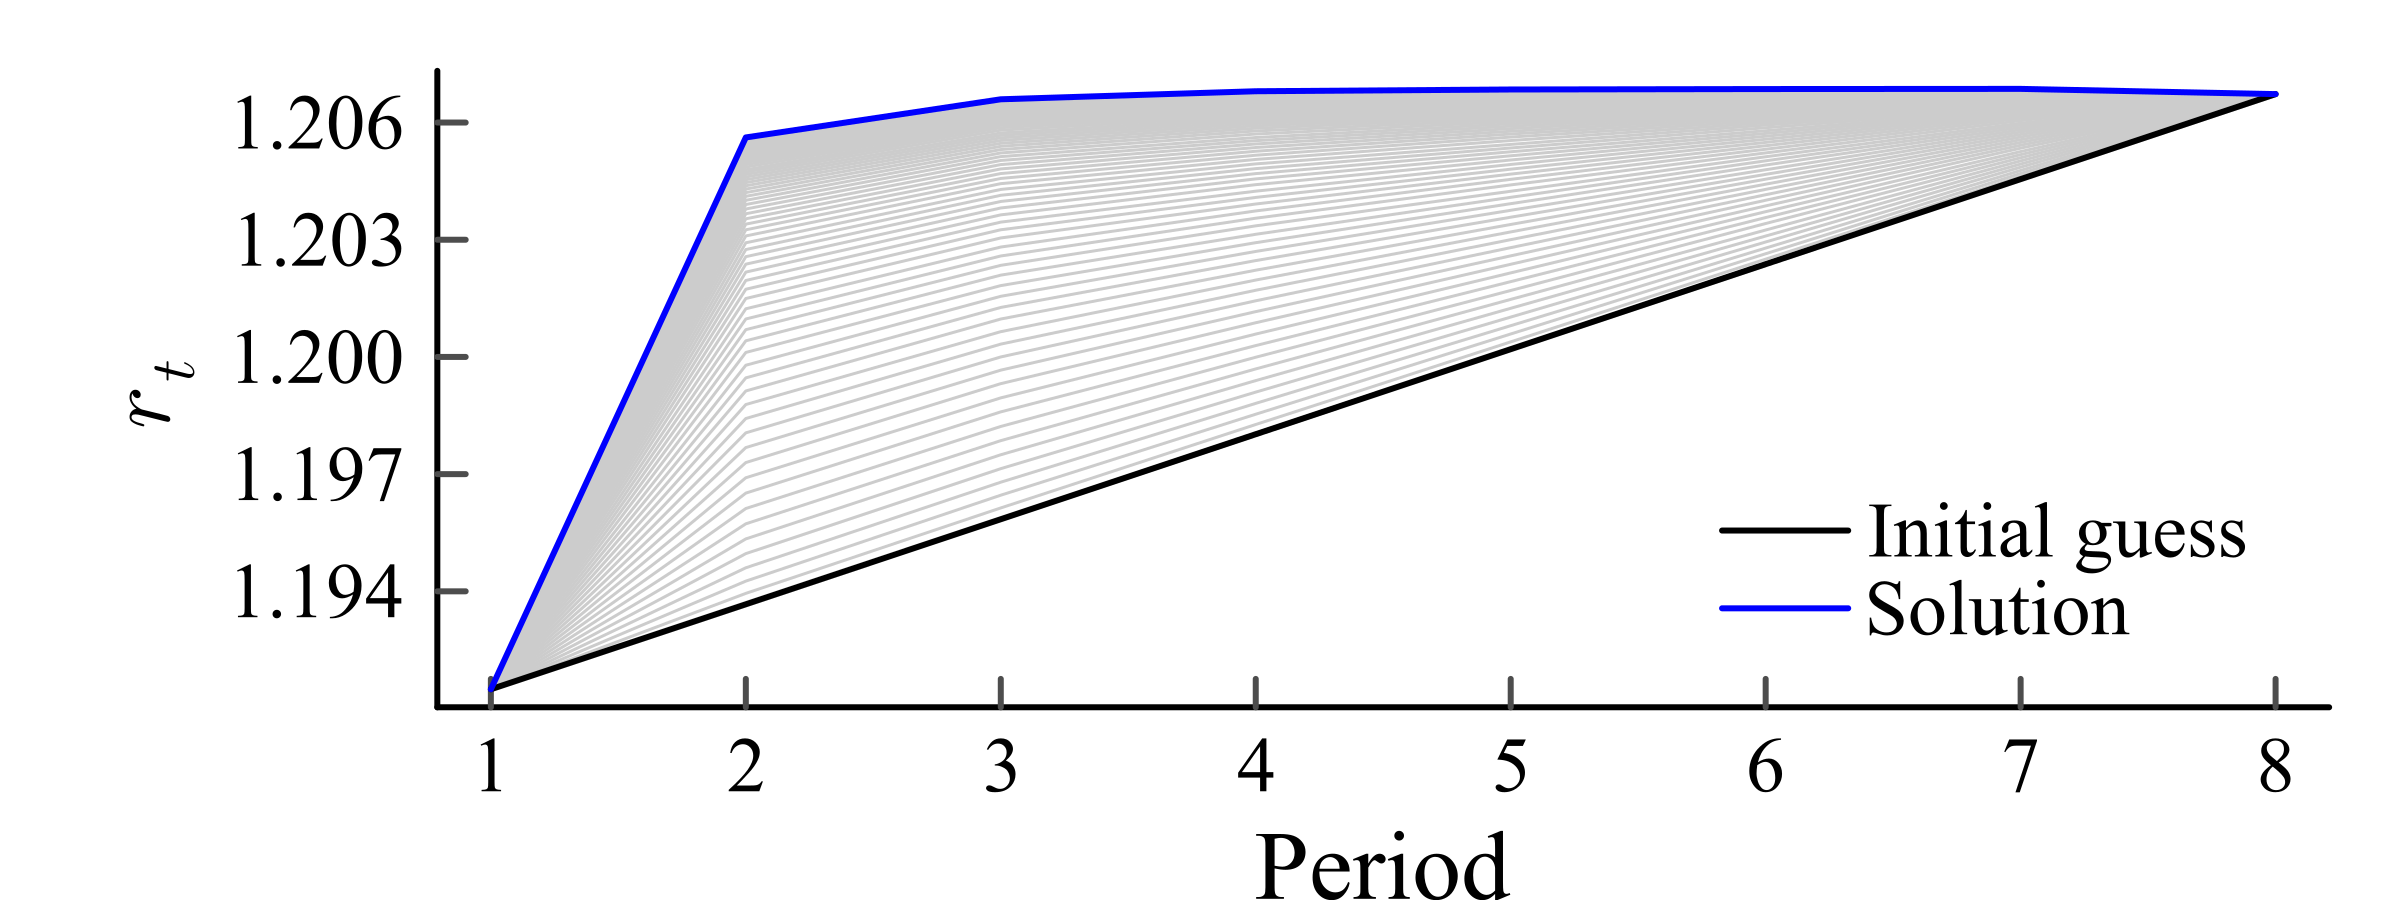

In [139]:
using Plots
using LaTeXStrings

p = plot(;
    xlabel="Period",
    ylabel=L"r_t",
    dpi=600,
    size=(400, 150),
    left_margin=5 * Plots.mm,

    # Fonts
    fontfamily="Times New Roman",
    guidefontsize=10,
    tickfontsize=8,
    legendfontsize=8,

    # Appearance
    background_color=:white,
    foreground_color_axis=:gray30,
    grid=false,
    framestyle=:axes,
    xticks=1:T,

    # Legend
    legend=:bottomright,
    legend_background_color=:transparent,
    legend_foreground_color=:transparent
)

# Intermediate iterations: excluded from the legend
for x in 2:(iter - 1)
    plot!(p, 1:T, r_t_iter[:, x];
        lc=:gray80, lw=0.5, label="")
end

# First iteration
plot!(p, 1:T, r_t_iter[:, 1];
    lc=:black, lw=1, label="Initial guess")

# Final iteration
if iter > 1
    plot!(p, 1:T, r_t_iter[:, iter];
        lc=:blue, lw=1, label="Solution")
end

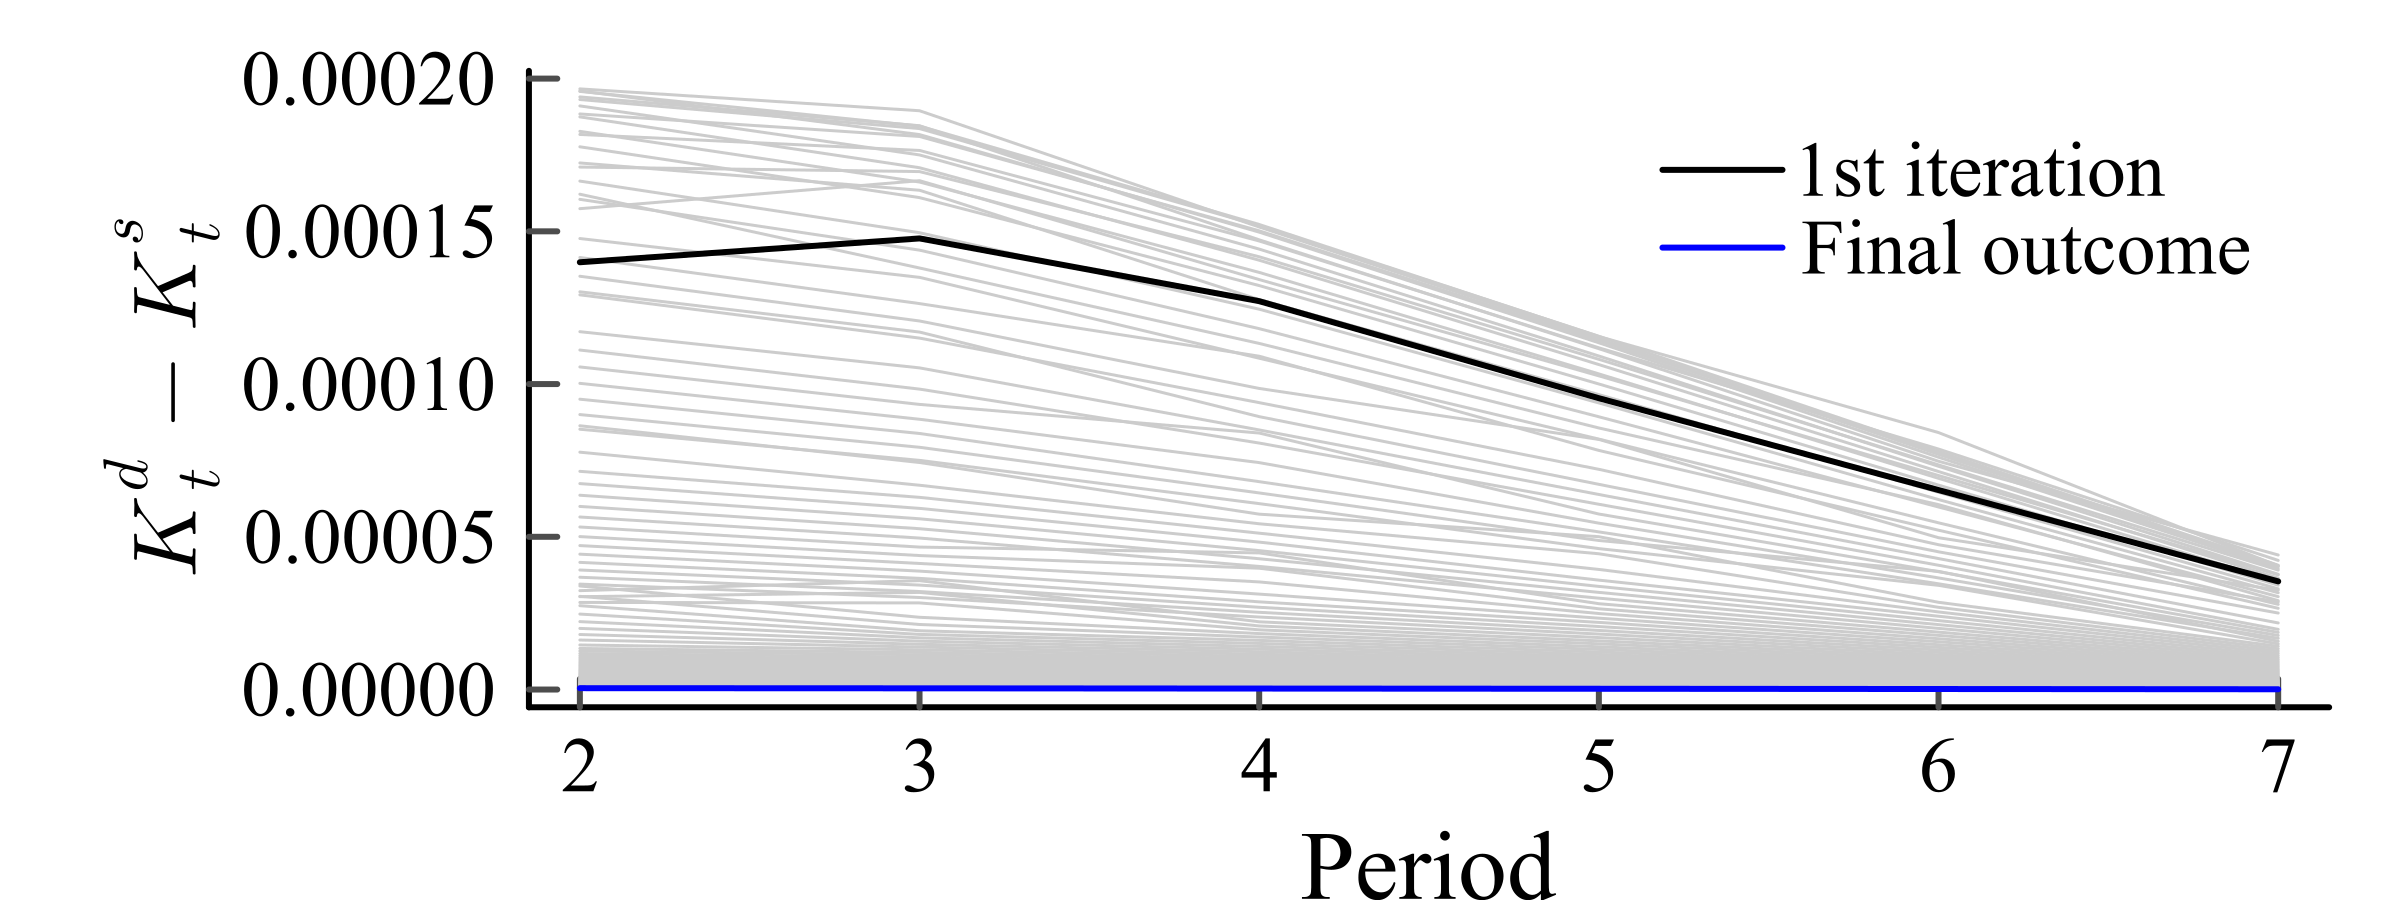

In [138]:
using Plots
using LaTeXStrings

last_iter = iter - 1
periods = 2:(T - 1)

p = plot(;
    xlabel="Period",
    ylabel=L"K_t^{d} - K_t^{s}",
    dpi=600,
    size=(400, 150),
    left_margin=5 * Plots.mm,

    # Fonts
    fontfamily="Times New Roman",
    guidefontsize=10,
    tickfontsize=8,
    legendfontsize=8,

    # Appearance
    background_color=:white,
    foreground_color_axis=:gray30,
    grid=false,
    framestyle=:axes,
    xticks=periods,

    # Legend
    legend=:best,
    legend_background_color=:transparent,
    legend_foreground_color=:transparent
)

# Intermediate iterations: excluded from the legend
for x in 2:(last_iter - 1)
    plot!(p, periods, excess_K_t[periods, x];
        lc=:gray80, lw=0.5, label="")
end

# First iteration
plot!(p, periods, excess_K_t[periods, 1];
    lc=:black, lw=1, label="1st iteration")

# Final computed outcome
if last_iter > 1
    plot!(p, periods, excess_K_t[periods, last_iter];
        lc=:blue, lw=1, label="Final outcome")
end

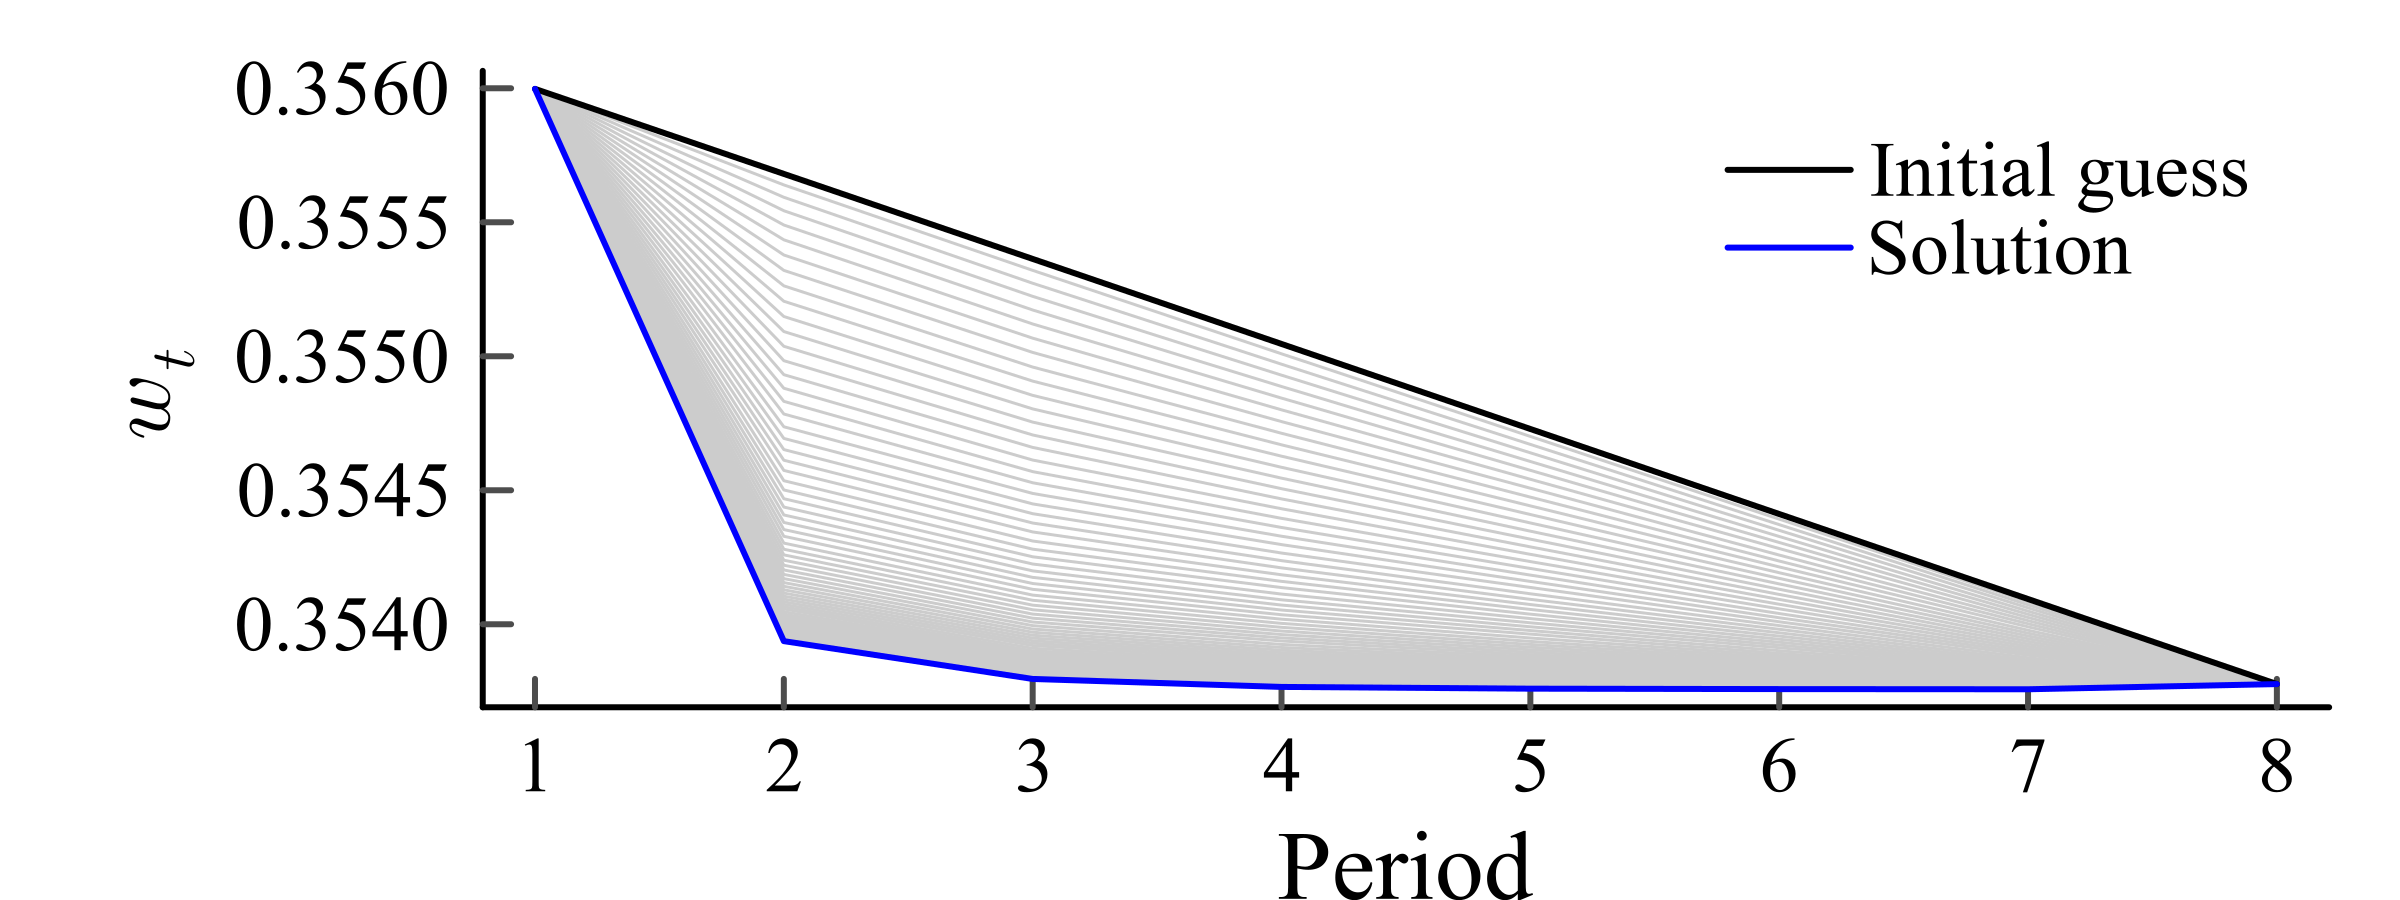

In [137]:
using Plots
using LaTeXStrings

p = plot(;
    xlabel="Period",
    ylabel=L"w_t",
    dpi=600,
    size=(400, 150),
    left_margin=5 * Plots.mm,

    # Fonts
    fontfamily="Times New Roman",
    guidefontsize=10,
    tickfontsize=8,
    legendfontsize=8,

    # Appearance
    background_color=:white,
    foreground_color_axis=:gray30,
    grid=false,
    framestyle=:axes,
    xticks=1:T,

    # Legend
    legend=:topright,
    legend_background_color=:transparent,
    legend_foreground_color=:transparent
)

# Intermediate iterations: excluded from the legend
for x in 2:(iter - 1)
    plot!(p, 1:T, w_t_iter[:, x];
        lc=:gray80, lw=0.5, label="")
end

# First iteration
plot!(p, 1:T, w_t_iter[:, 1];
    lc=:black, lw=1, label="Initial guess")

# Final iteration
if iter > 1
    plot!(p, 1:T, w_t_iter[:, iter];
        lc=:blue, lw=1, label="Solution")
end

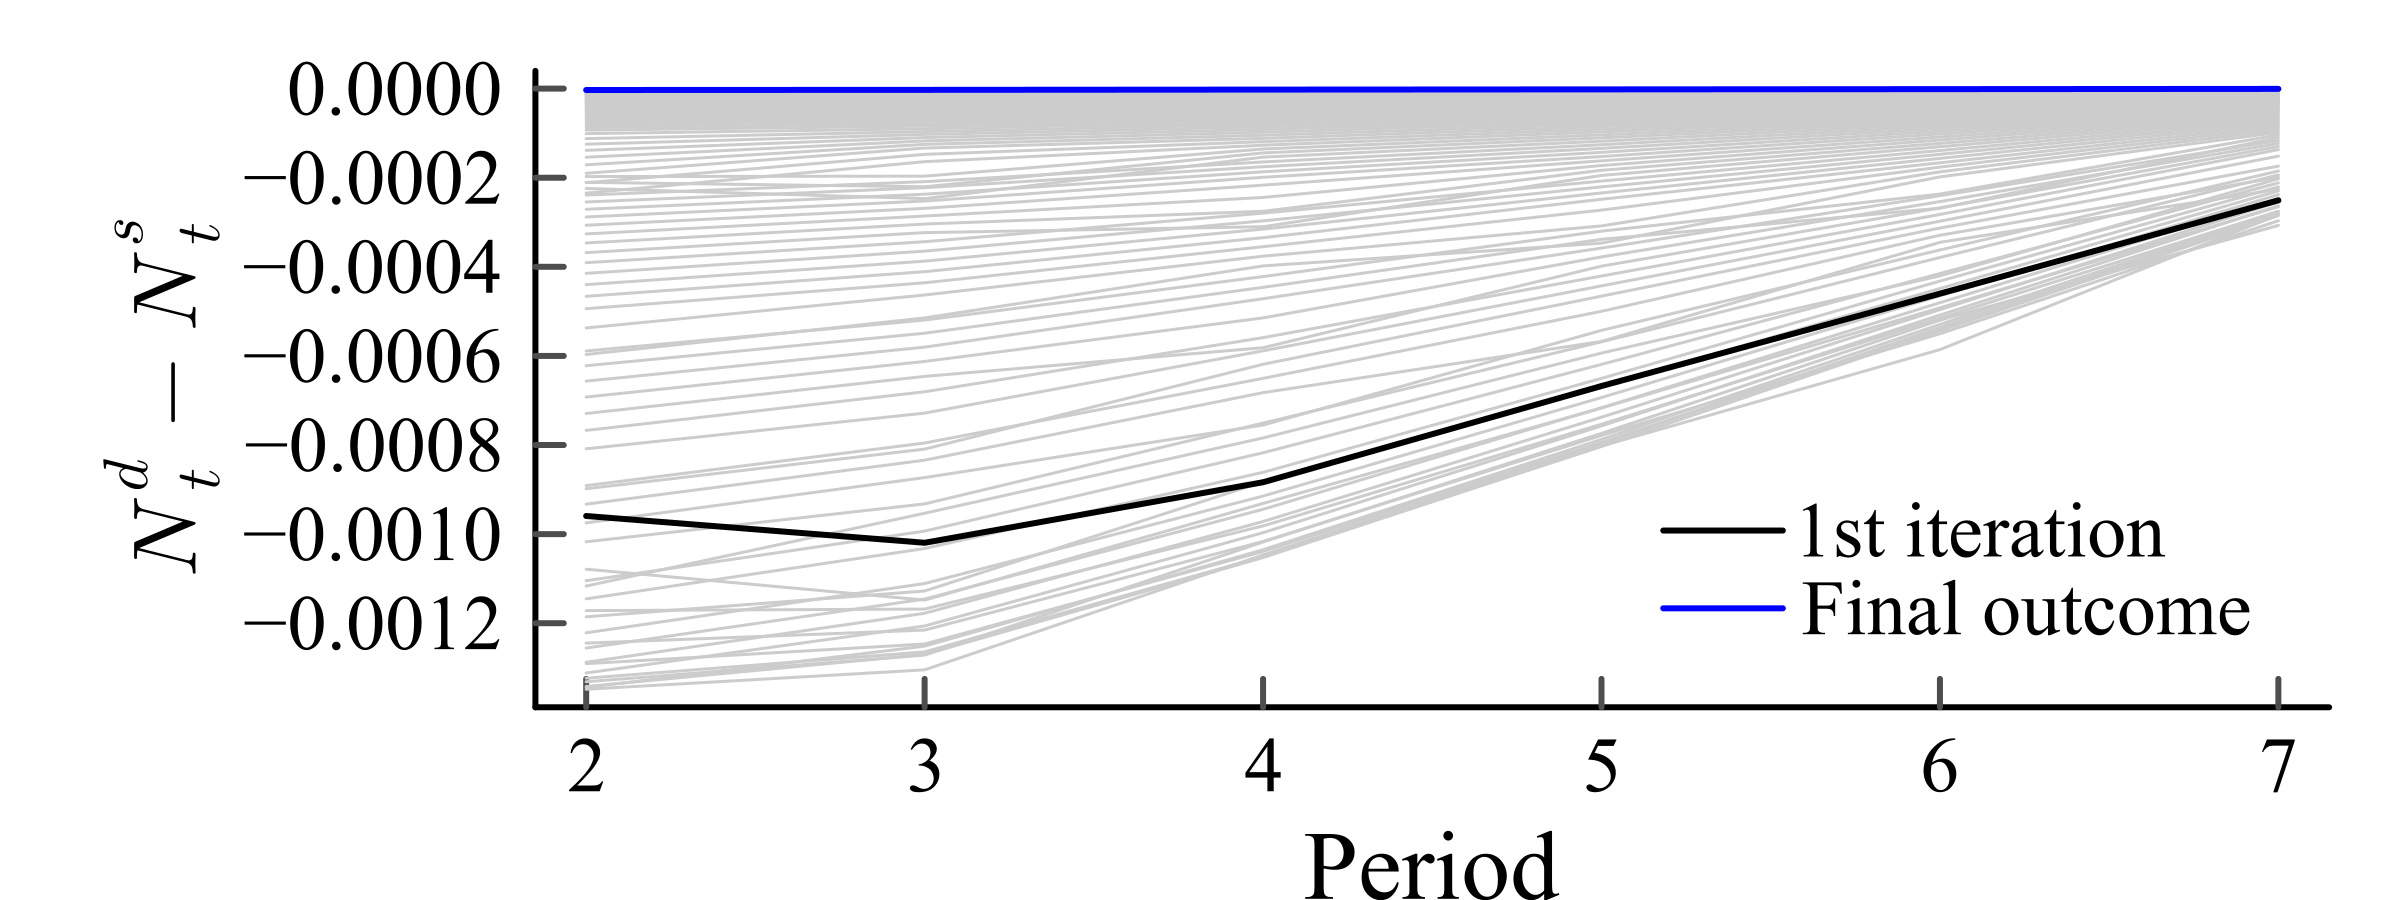

In [136]:
using Plots
using LaTeXStrings

last_iter = iter - 1
periods = 2:(T - 1)

p = plot(;
    xlabel="Period",
    ylabel=L"N_t^{d} - N_t^{s}",
    dpi=600,
    size=(400, 150),
    left_margin=5 * Plots.mm,

    # Fonts
    fontfamily="Times New Roman",
    guidefontsize=10,
    tickfontsize=8,
    legendfontsize=8,

    # Appearance
    background_color=:white,
    foreground_color_axis=:gray30,
    grid=false,
    framestyle=:axes,
    xticks=periods,

    # Legend
    legend=:best,
    legend_background_color=:transparent,
    legend_foreground_color=:transparent
)

# Intermediate iterations: excluded from the legend
for x in 2:(last_iter - 1)
    plot!(p, periods, excess_N_t[periods, x];
        lc=:gray80, lw=0.5, label="")
end

# First iteration
plot!(p, periods, excess_N_t[periods, 1];
    lc=:black, lw=1, label="1st iteration")

# Final computed outcome
if last_iter > 1
    plot!(p, periods, excess_N_t[periods, last_iter];
        lc=:blue, lw=1, label="Final outcome")
end

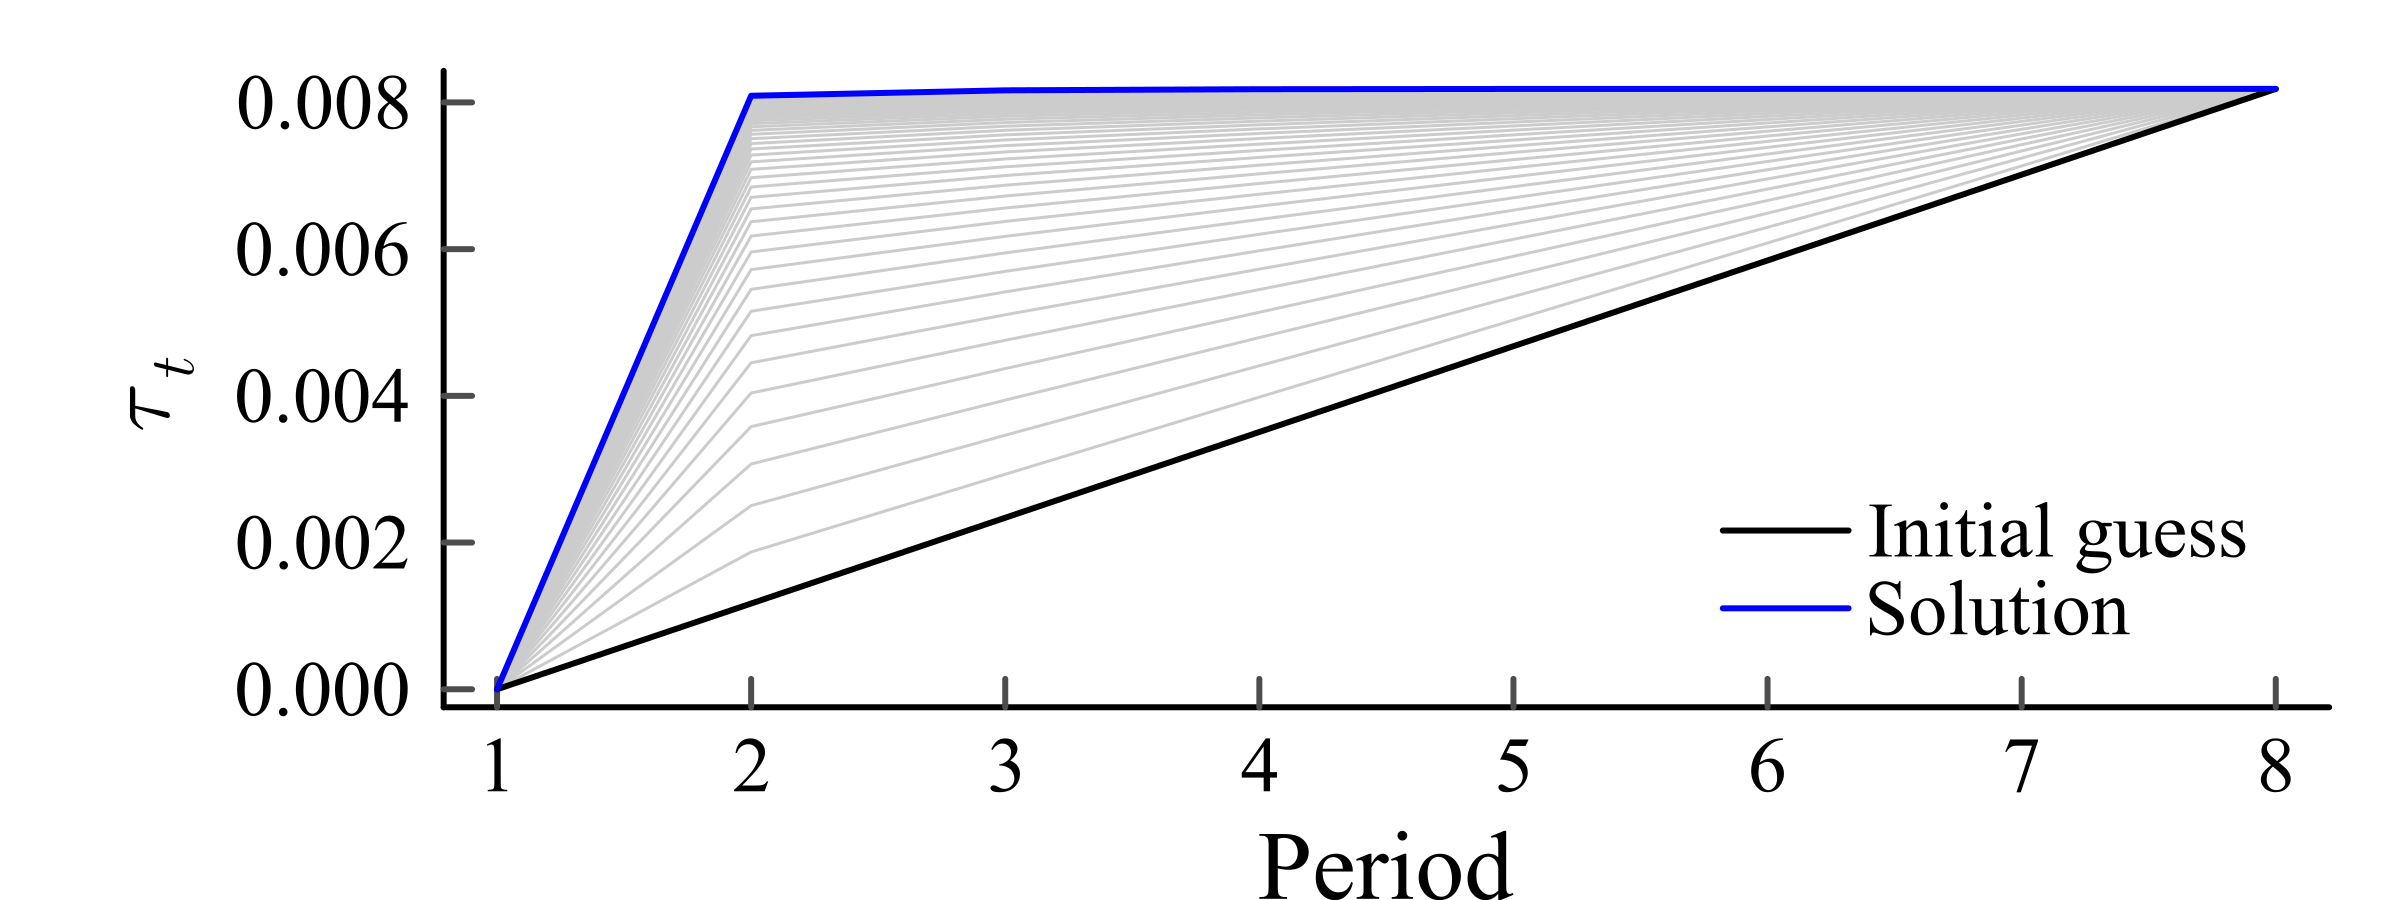

In [135]:
using Plots
using LaTeXStrings

p = plot(;
    xlabel="Period",
    ylabel=L"\tau_t",
    dpi=600,
    size=(400, 150),
    left_margin=5 * Plots.mm,

    # Fonts
    fontfamily="Times New Roman",
    guidefontsize=10,
    tickfontsize=8,
    legendfontsize=8,

    # Appearance
    background_color=:white,
    foreground_color_axis=:gray30,
    grid=false,
    framestyle=:axes,
    xticks=1:T,

    # Legend
    legend=:bottomright,
    legend_background_color=:transparent,
    legend_foreground_color=:transparent
)

# Intermediate iterations: excluded from the legend
for x in 2:(iter - 1)
    plot!(p, 1:T, τ_t_iter[:, x];
        lc=:gray80, lw=0.5, label="")
end

# First iteration
plot!(p, 1:T, τ_t_iter[:, 1];
    lc=:black, lw=1, label="Initial guess")

# Final iteration
if iter > 1
    plot!(p, 1:T, τ_t_iter[:, iter];
        lc=:blue, lw=1, label="Solution")
end

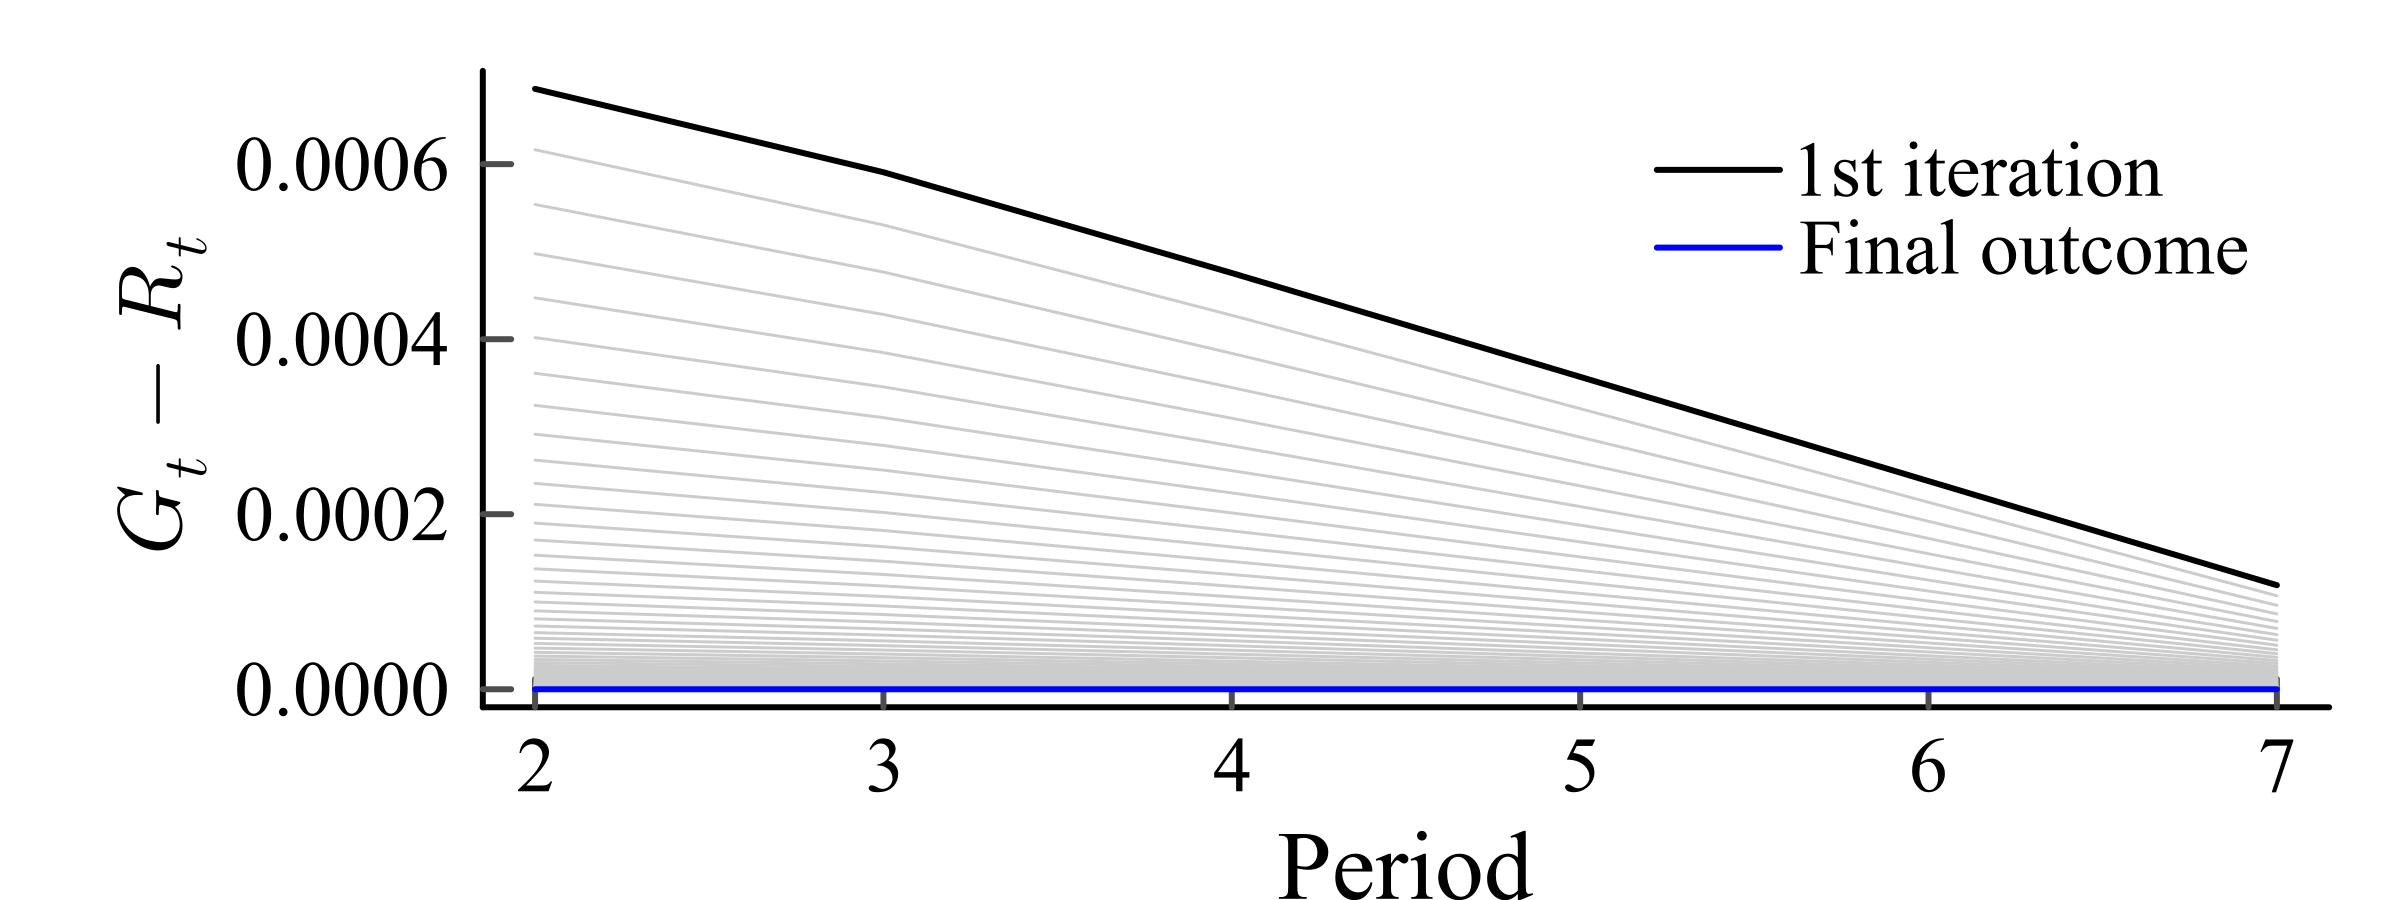

In [134]:
using Plots
using LaTeXStrings

last_iter = iter - 1
periods = 2:(T - 1)

p = plot(;
    xlabel="Period",
    ylabel=L"G_t - R_t",
    dpi=600,
    size=(400, 150),
    left_margin=5 * Plots.mm,

    # Fonts
    fontfamily="Times New Roman",
    guidefontsize=10,
    tickfontsize=8,
    legendfontsize=8,

    # Appearance
    background_color=:white,
    foreground_color_axis=:gray30,
    grid=false,
    framestyle=:axes,
    xticks=periods,

    # Legend
    legend=:best,
    legend_background_color=:transparent,
    legend_foreground_color=:transparent
)

# Intermediate iterations: excluded from the legend
for x in 2:(last_iter - 1)
    plot!(p, periods, excess_s_t[periods, x];
        lc=:gray80, lw=0.5, label="")
end

# First iteration
plot!(p, periods, excess_s_t[periods, 1];
    lc=:black, lw=1, label="1st iteration")

# Final computed outcome
if last_iter > 1
    plot!(p, periods, excess_s_t[periods, last_iter];
        lc=:blue, lw=1, label="Final outcome")
end

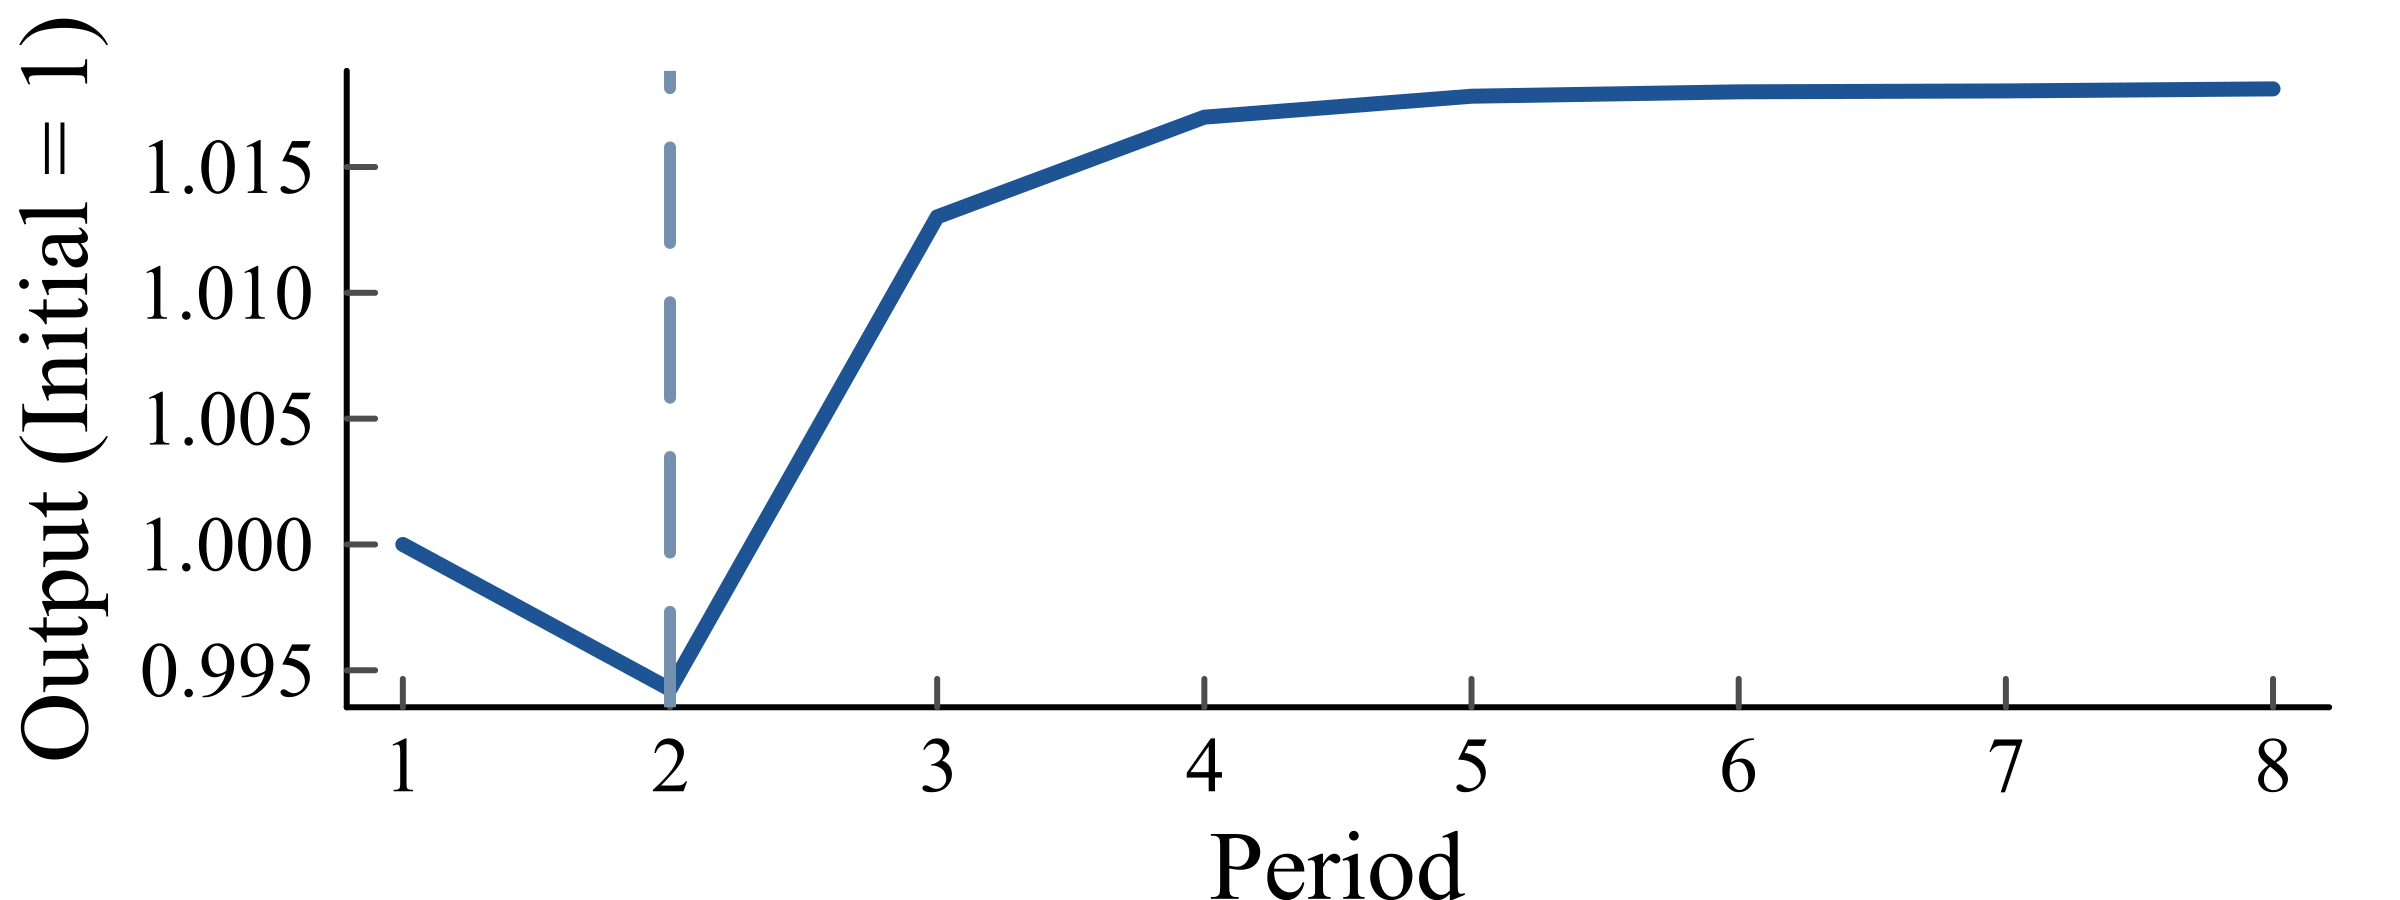

In [142]:
using Plots

blue = RGB(0.12, 0.33, 0.58)
blue_gray = RGB(0.45, 0.57, 0.68)

# Output transition
plot(1:T, Y_t ./ Y_t[1];
    xlabel="Period",
    ylabel="Output (Initial = 1)",
    lw=2.5,
    lc=blue,
    legend=false,
    dpi=600,
    size=(400, 150),

    # Fonts
    fontfamily="Times New Roman",
    guidefontsize=10,
    tickfontsize=8,

    # Appearance
    background_color=:white,
    foreground_color_axis=:gray30,
    grid=false,
    framestyle=:axes,
    xticks=1:T
)

# Policy change in period 2
vline!([2]; lw=2, lc=blue_gray, ls=:dash, label="")

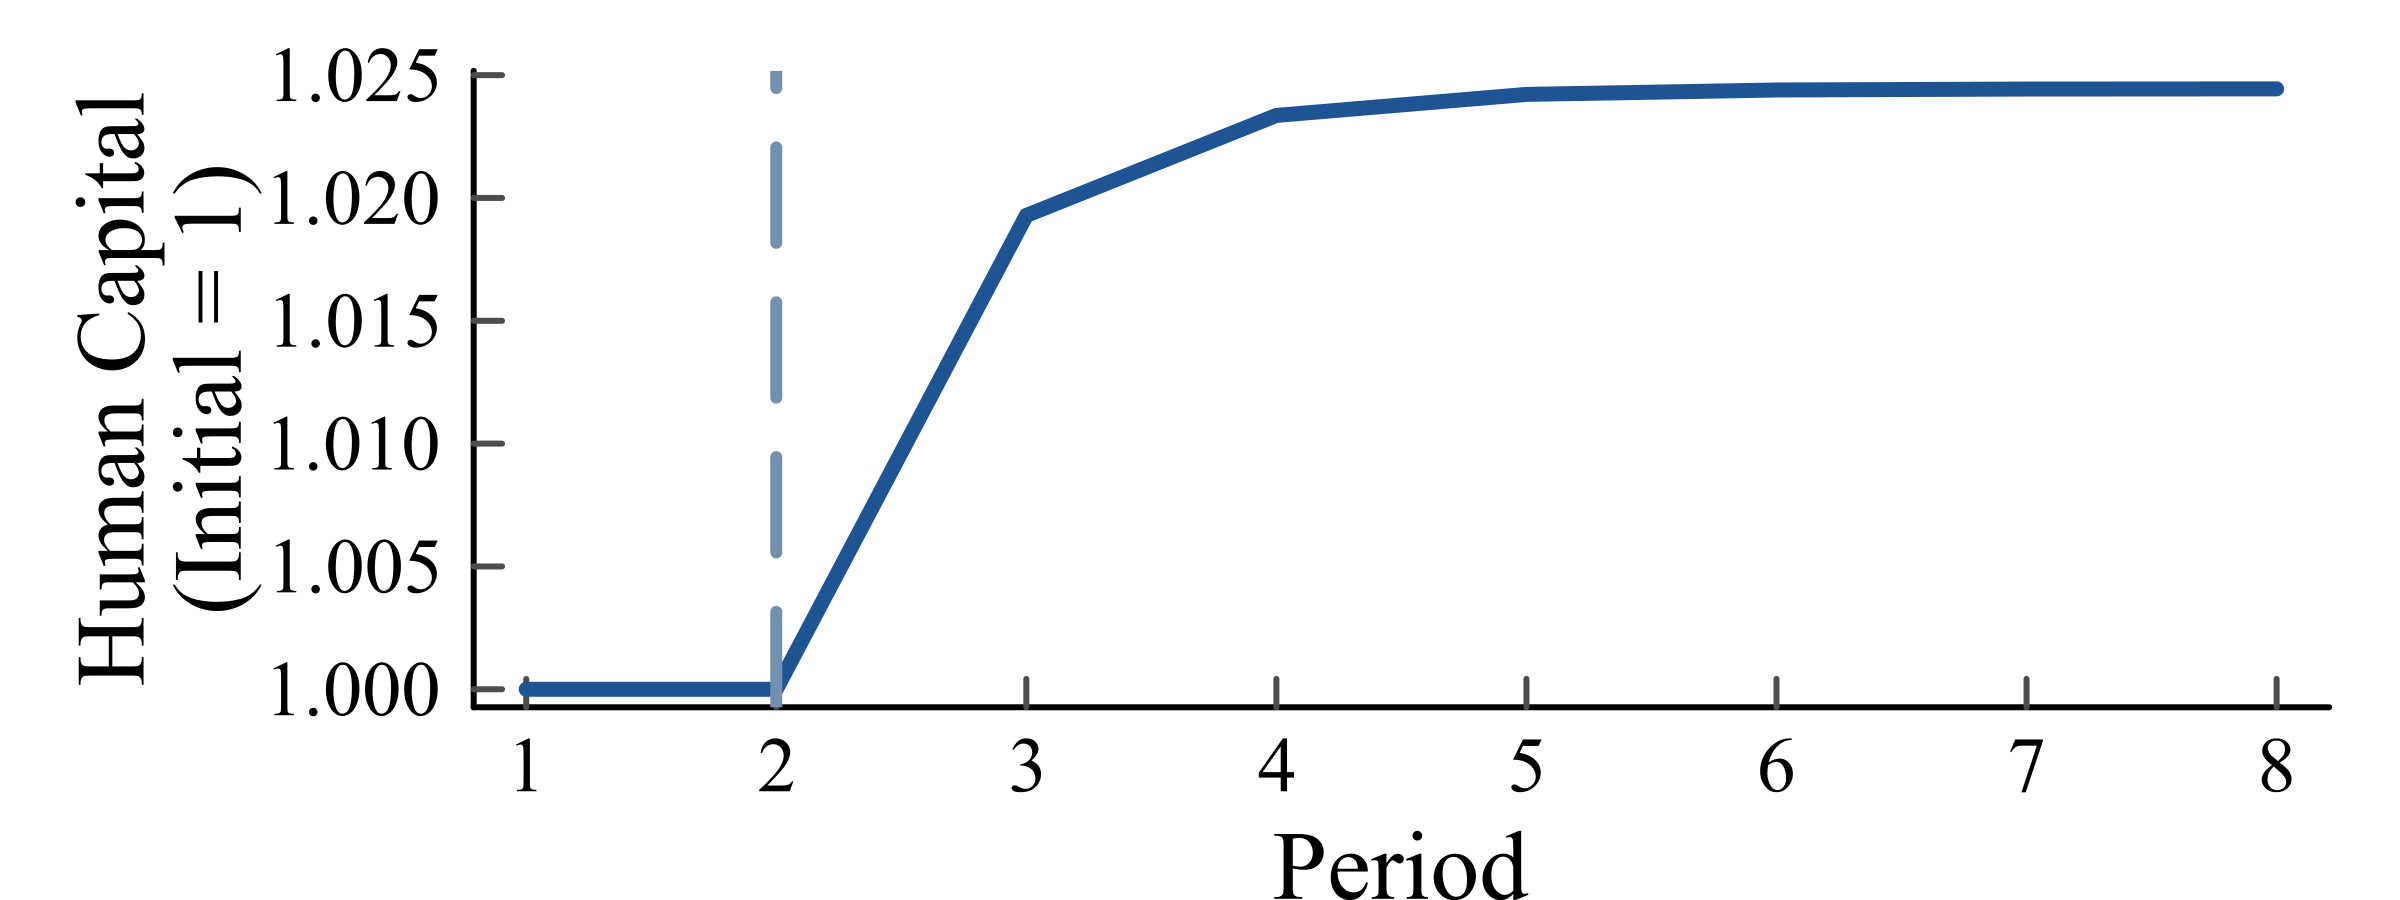

In [114]:
using Plots

blue = RGB(0.12, 0.33, 0.58)
blue_gray = RGB(0.45, 0.57, 0.68)

# Human capital transition
plot(1:T, N_t ./ N_t[1];
    xlabel="Period",
    ylabel="Human Capital\n(Initial = 1)",
    lw=2.5,
    lc=blue,
    legend=false,
    dpi=600,
    size=(400, 150),
    left_margin=5 * Plots.mm,

    # Fonts
    fontfamily="Times New Roman",
    guidefontsize=10,
    tickfontsize=8,

    # Appearance
    background_color=:white,
    foreground_color_axis=:gray30,
    grid=false,
    framestyle=:axes,
    xticks=1:T
)

# Policy change in period 2
vline!([2]; lw=2, lc=blue_gray, ls=:dash, label="")

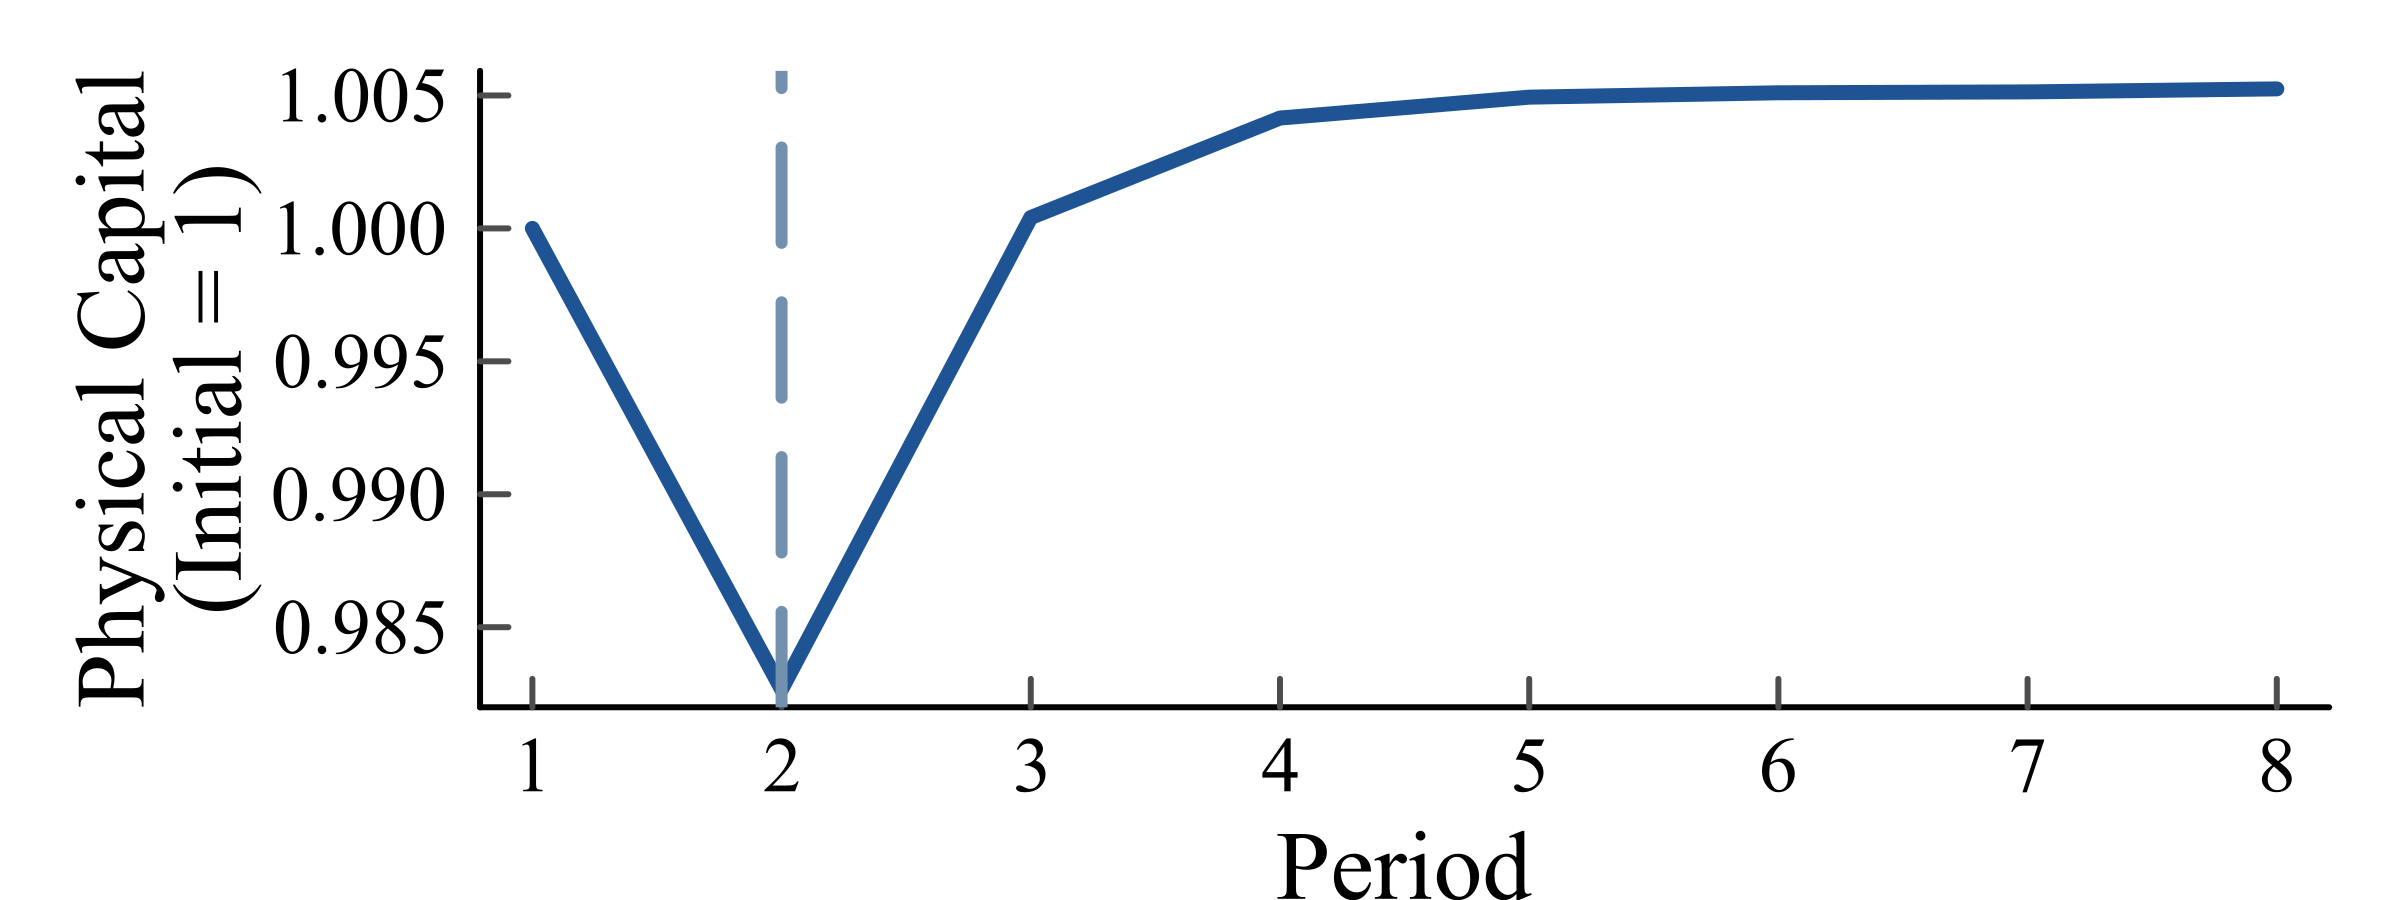

In [115]:
# Physical capital
using Plots

blue = RGB(0.12, 0.33, 0.58)
blue_gray = RGB(0.45, 0.57, 0.68)

plot(1:T, K_t./K_t[1];
    xlabel="Period",
    ylabel="Physical Capital\n(Initial = 1)",
    lw=2.5,
    lc=blue,
    legend=false,
    dpi=600,
    size=(400, 150),
    left_margin=5 * Plots.mm,

    # Fonts
    fontfamily="Times New Roman",
    guidefontsize=10,
    tickfontsize=8,

    # Appearance
    background_color=:white,
    foreground_color_axis=:gray30,
    grid=false,
    framestyle=:axes,
    xticks=1:T
)

# Policy change in period 2
vline!([2]; lw=2, lc=blue_gray, ls=:dash, label="")

In [116]:
# Compute CEV
# Benchmark: initial steady state without the reform
p_base = Params(β, γ, p_e, θ, B, κ, α, s_old)

cy_base, co_base, e_base =
    household(N0, w0, r0, τ0, p_base)

hchild_base = θ + B * e_base^κ

U_base = log(cy_base) +
         β * log(co_base) +
         γ * log(hchild_base)

# Cohorts explicitly solved by the transition loop
# cohorts = 2:(T - 1)
cohorts = 1:T

cy_cohort = fill(NaN, T) # young-age consumption by cohort t
co_cohort = fill(NaN, T) # old-age consumption by cohort t
hchild_cohort = fill(NaN, T) # child's human capital by cohort
U_cohort = fill(NaN, T) # utility by cohort

# Recompute allocations using the final price paths
for t in cohorts
    p_cohort = Params(β, γ, p_e, θ, B, κ, α, s_t[t])
    h = t == 2 ? N0 : N_t[t]

    # Matches the interest-rate convention in your current solver
    cy, co, e = household(
        h, w_t[t], r_t[t], τ_t[t], p_cohort
    )

    cy_cohort[t] = cy
    co_cohort[t] = co
    hchild_cohort[t] = θ + B * e^κ

    U_cohort[t] = log(cy) +
                  β * log(co) +
                  γ * log(hchild_cohort[t])
end

# Consumption-equivalent welfare change, in percent
CEV_pct = 100 .* expm1.((U_cohort .- U_base) ./ (1 + β));

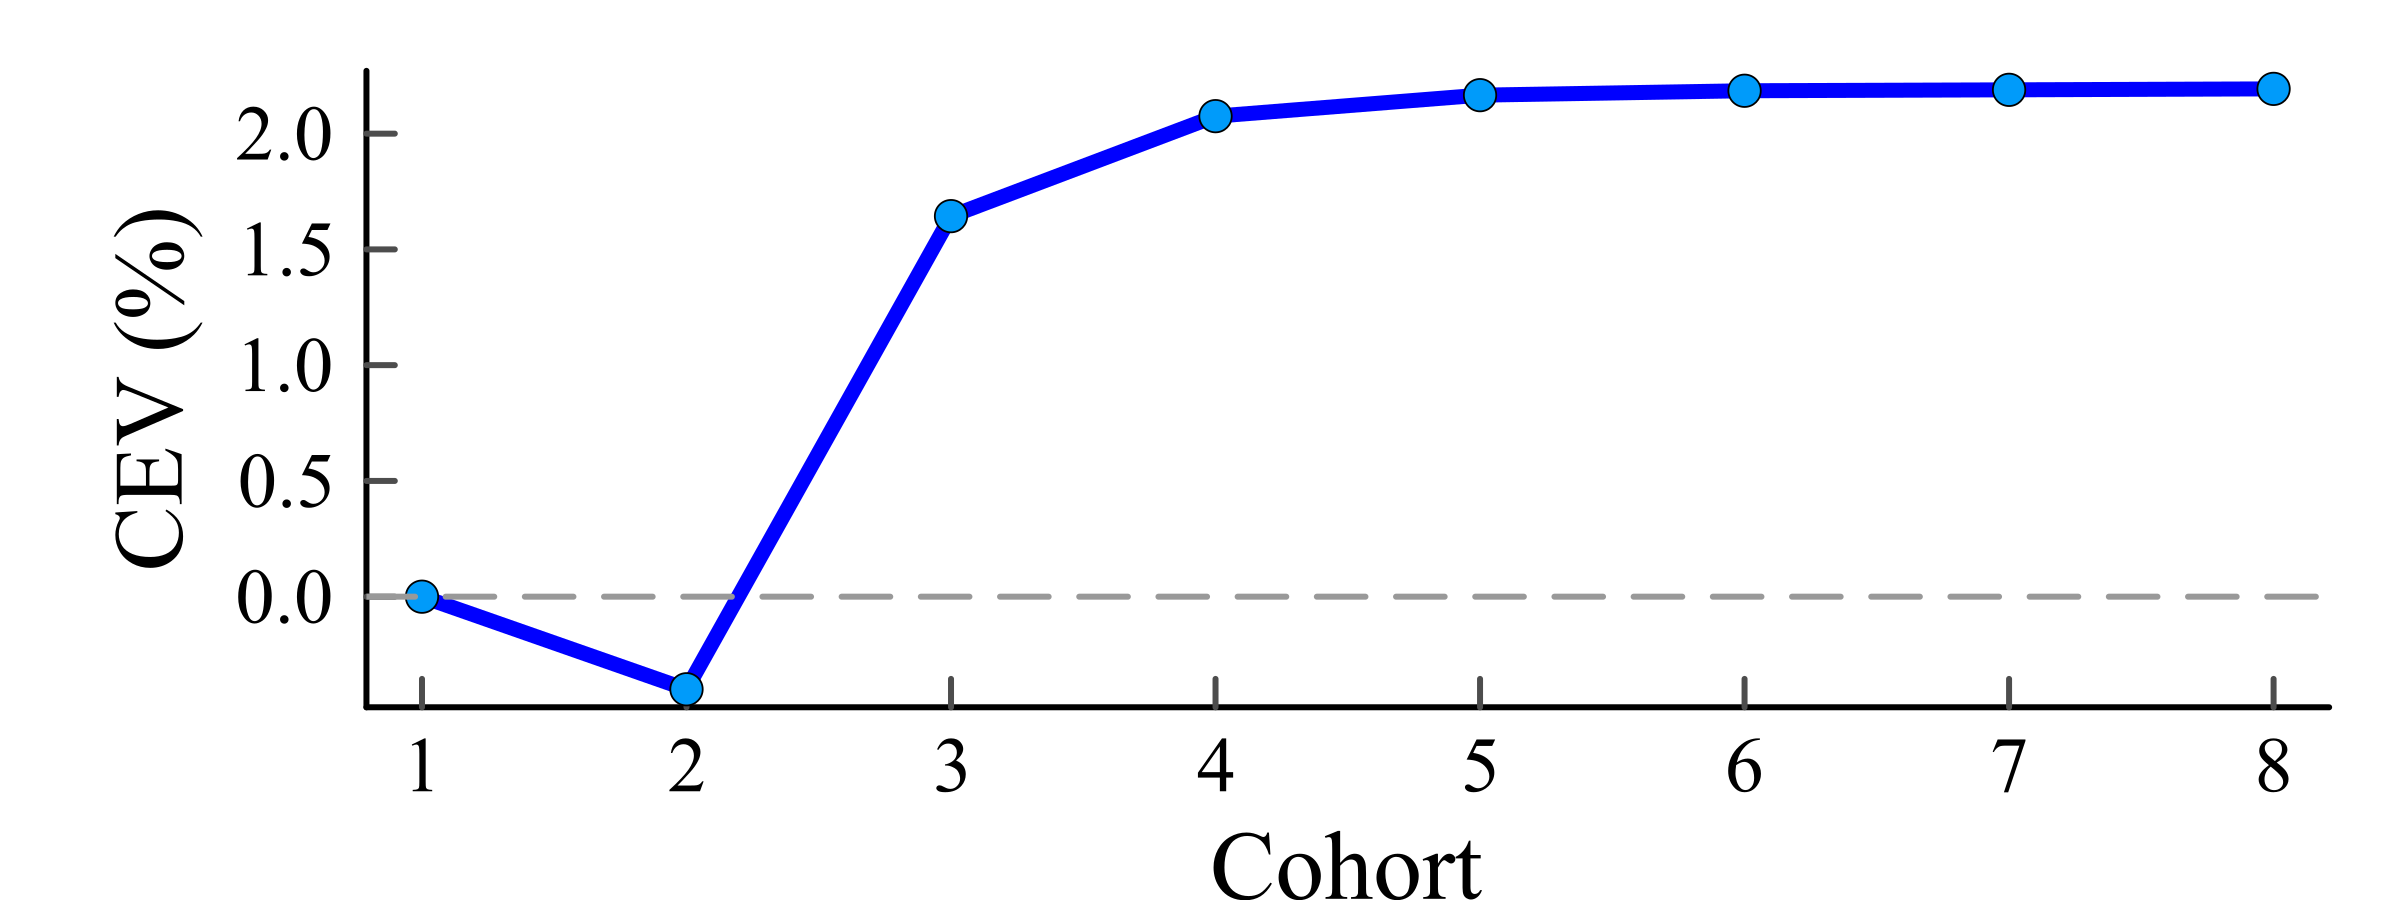

In [117]:
using Plots

plot(cohorts, CEV_pct[cohorts];
    xlabel="Cohort",
    ylabel="CEV (%)",
    lc=:blue,
    lw=2.5,
    marker=:circle,
    markersize=3,
    legend=false,
    dpi=600,
    size=(400, 150),
    left_margin=5 * Plots.mm,

    fontfamily="Times New Roman",
    guidefontsize=10,
    tickfontsize=8,

    background_color=:white,
    foreground_color_axis=:gray30,
    grid=false,
    framestyle=:axes,
    xticks=cohorts
)

# Zero welfare change
hline!([0.0];
    lc=:gray60, lw=1, ls=:dash, label="")

### Tips for solving transitional dynamics of multi-period models

- We adopted a two-period model intentionally to get the gist of the algorithm for transitional dynamics

- Infinite horizon model is also relatively easy

- What makes it so complicated when solving transitional dynamics for multi-period model?

- We need to consider the household solutions separately between cohorts who are alive both before and after the shock (e.g., policy) and those who are born only after the shock.

- Typically we consider the shock is MIT (), so the households at the initial steady state do not expect that to happen.

- This means that before the shock they make decisions given the old economic environment and after the shock hits they reoptimize their behavior. 

### Tips for solving transitional dynamics in multi-period models

- We intentionally adopted a two-period OLG model to understand the basic algorithm for computing transitional dynamics.

- Extending the algorithm to an infinite-horizon representative-agent model is also relatively straightforward (next week).

- **What makes computing transitional dynamics more complicated in multi-period OLG models?**

- The basic logic of the algorithm remains the same, but the main challenge is that multiple generations coexist, and in particular, that we need to distinguish between:
    - **Existing generations:** Households that were born before the shock and are still alive when it occurs.
    - **Future generations:** Households that are born after the shock.

- Typically, we consider an MIT shock: an unexpected shock that occurs at a particular point in time and is perfectly understood once it occurs. Households in the initial steady state do not anticipate the shock.

- Therefore, households make their decisions before the shock based on the initial steady-state economic environment. Once the shock occurs, surviving households **reoptimize their remaining lifetime decisions**, taking into account their accumulated assets, remaining lifetime, and the expected future path of prices and policies. Decisions made before the shock cannot be reversed.

    - In our two-period model example, the parent generation is technically a future generation since they had not yet made any decisions before the policy introduction.

    - Also, the old generation does not reoptimize their behavior since their choice is already sunk (savings in the young age, which determine consumption in old age).

![Multi-period lifecycle](figures/Lec06_multi.png)

- Households born after the shock, on the other hand, make their lifetime decisions taking the new economic environment into account from the beginning.

- Therefore, we need to prepare a solver for the existing generation that uses their optimal choices based on the old environment before the shock hits and that computes the optimal choices after the shock hits.

![Reoptimize](figures/Lec06_reoptimize.png)